<table style="width: 100%; margin-left: auto; margin-right: auto; background-color: white;">
<tbody>
<tr>

<td style="text-align: center; width: 12%;"><img src=img/brasil-brasao.png alt="" /></td>

<td style="width: 68%;">
<h2 style="text-align: center; margin-top: 1%;">Rep&uacute;blica Federativa do Brasil</h2>
<h2 style="text-align: center; margin-top: 1%;">Minist&eacute;rio da Educa&ccedil;&atilde;o</h2>
<h2 style="text-align: center; margin-top: 1%;">Universidade Federal do Amazonas</h2>
<h2 style="text-align: center; margin-top: 1%;">Instituto de Computa&ccedil;&atilde;o</h2>
</td>

<td style="width: 12%;"><img src="img/UFAM-logo.png" alt="" /></td>

</tr>
</tbody>
</table>

---

# Ciência de Dados
## Trabalho Prático II: Modelagem de Dados

_Professor Dr. Marco Cristo_

In [ ]:
# Imports
from google.colab import drive
drive.mount('/content/drive')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import sklearn
import sys
import os

# --- Bibliotecas para Modelagem e Avaliação ---
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, make_scorer

# --- Modelos ---
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# --- Outras ---
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suprimir avisos de convergência (comuns em redes neurais e SVM)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Alunos:**  `Cristiano Cardoso, Davi Carlos e Matheus Santarém` <br>
**E-mail:** `cristiano.lima@icomp.ufam.edu.br, davicaf@icomp.ufam.edu.br e matheus.santarem@icomp.ufam.edu.br`

In [ ]:
print("Python", sys.version)
print("--------")
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("SKLearn:", sklearn.__version__)

Python 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
--------
Pandas: 2.2.2
Numpy: 2.0.2
SKLearn: 1.6.1


#### __Preliminares__: Inicialmente, vamos preparar os dados conforme estabelecido no primeiro trabalho prático. Para tanto, obtenha os dados das cidades dos membros da sua equipe no diretório `data`.

In [ ]:
pasta_do_trabalho = "TP2 CRISTIANODAVIMATHEUS"
base_dir = '/content/drive/MyDrive/' + pasta_do_trabalho + '/'

DATA_PQT = base_dir + 'data/enem2019.parquet'
MUNICIPIOS = ['São Gonçalo', 'Guarulhos', 'Recife'] # Use o que foi especificado para os membros da sua equipe.

In [ ]:
import os

data_path = base_dir + 'data/'
print(f"Verificando o diretório: {data_path}")
if not os.path.exists(data_path):
    print(f"Erro: O diretório '{data_path}' não existe.")
else:
    print(f"Conteúdo do diretório '{data_path}':")
    print(os.listdir(data_path))

# Caminho do arquivo
df_enem = pd.read_parquet(DATA_PQT)
df_enem.shape

Verificando o diretório: /content/drive/MyDrive/TP2 CRISTIANODAVIMATHEUS/data/
Conteúdo do diretório '/content/drive/MyDrive/TP2 CRISTIANODAVIMATHEUS/data/':
['enem2019.parquet']


(599982, 56)

In [ ]:
# Remove todas as instâncias que não possuem valores para as colunas NO_MUNICIPIO_NASCIMENTO ou SG_UF_NASCIMENTO.
# Para as colunas CO_PROVA_CN, CO_PROVA_CH, CO_PROVA_LC, CO_PROVA_MT e TP_STATUS_REDACAO, remove apenas as instâncias
# onde todos esses valores encontram-se ausentes.
crit = ((df_enem.CO_PROVA_CN.isnull())&(df_enem.CO_PROVA_CH.isnull())&
        (df_enem.CO_PROVA_LC.isnull())&(df_enem.CO_PROVA_MT.isnull())&
        (df_enem.TP_STATUS_REDACAO.isnull()))
df_enem = df_enem[~crit]
display(df_enem.shape)

notas = [c for c in df_enem.columns if 'NU_NOTA' in c]
for c in notas:
    df_enem[c] = df_enem[c].fillna(0)

cods = [c for c in df_enem.columns if 'CO_PROVA' in c]
for c in cods:
    df_enem[c] = df_enem[c].fillna(500)

# Usando campo NU_IDADE, é criado FAIXA_ETARIA com os seguintes intervalos
# Instâncias com idade inferior a 10 ou superior a 100 anos sao removidas
def to_faixas(idade):
    if idade<18: return '10-18'
    elif idade<22: return '18-22'
    elif idade<26: return '22-26'
    elif idade<33: return '26-33'
    elif idade<40: return '33-40'
    elif idade<55: return '40-55'
    elif idade<63: return '55-65'
    elif idade<70: return '65-70'
    else: return '70-100'

df_enem = df_enem[(df_enem.NU_IDADE>=10)&(df_enem.NU_IDADE<=100)]
df_enem['FAIXA_ETARIA'] = df_enem.NU_IDADE.apply(to_faixas)

display(df_enem.FAIXA_ETARIA.value_counts())

nota_media = df_enem.NU_NOTA_REDACAO.mean()
df_enem['TARGET'] = df_enem.NU_NOTA_REDACAO.apply(lambda v: 1 if v>nota_media else 0)

cols_to_use = ['FAIXA_ETARIA', 'NO_MUNICIPIO_RESIDENCIA', 'TP_SEXO', 'TP_ESTADO_CIVIL',
               'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ESCOLA', 'CO_PROVA_CH',
               'CO_PROVA_LC', 'NU_NOTA_CH', 'NU_NOTA_LC', 'TP_LINGUA', 'Q001',
               'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q021', 'Q022', 'Q024', 'Q025']

df_enem_c = df_enem[df_enem.NO_MUNICIPIO_PROVA.isin(MUNICIPIOS)][cols_to_use + ['TARGET']].copy()

(461563, 58)

,count
FAIXA_ETARIA,
18-22,193068
10-18,121679
22-26,59240
26-33,42011
33-40,22444
40-55,20065
55-65,2462
65-70,495
70-100,99


<div class="alert alert-info" >
<b>1 - MODELAGEM:</b> Usando o dataset <b>df_enem_c</b>, o seu objetivo é prever que alunos vão obter uma nota na redação acima da nota média observada nas cidades associadas com a sua equipe. Para tanto, prepare um pipeline de comparação justo entre os métodos, onde:
    
- Variáveis categóricas devem ser codificadas com One-hot;
- Variáveis numéricas devem ser padronizadas (z-score);
- Todos os métodos comparados devem ser otimizados (usando uma ténica de busca em _grid_ e validação cruzada) de acordo com o conjunto _mínimo_ de hiper-parâmetros descritos na tabela abaixo:

| Método | Número mínimo de parâmetros a serem avaliados |
|-----------|-------|
| __Naive Bayes__ |  |
| __Logistic Regression__ | - __C__: 0.1, 1, 10<br>- __penalty__: L2<br>- __solver__: lbfgs, liblinear |
| __Decision Tree__ | - __max_depth__: None, 8, 16<br>- __min_samples_leaf__: 1, 5, 18 |
| __Support Vector Machine__ | - __C__: 0.5, 1, 4<br>- __kernel__: linear, rbf<br>- __gamma__: scale |
| __Neural Network__ | - __hidden_layer_sizes__: (64,), (128,)<br>- __activation__: relu, tanh<br>- __alpha__: 1e-4, 1e-3<br>- __learning_rate_init__: 1e-3 |
| __Random Forest__ | - __n_estimators__: 200, 400<br>- __max_depth__: None, 12<br>- __min_samples_leaf__: 1, 5 |
| __Gradient Boosting__ | - __learning_rate__: 0.05, 0.1<br>- __max_depth__: None, 8, 16<br>- __l2_regularization__: 0.0, 1.0 |

<b>2 - AVALIAÇÃO COMPARATIVA:</b> Os resultados devem ser comparados usando as métricas __Acurácia__, __F1__ e __AUC__. Em particular, todos os métodos devem ser comparados entre si quanto à significância estatística das diferenças entre os AUCs obtidos. Para isso, use o teste não paramétrico de Wilcoxon. Ao fim, as seguintes tabelas devem ser preenchidas:

| Método | Acurácia | F1 | AUC |
|--------|----------|----|-----|
| Naive Bayes |  |  |  |
| Logistic Regression |  |  |  |
| Decision Tree |  |  |  |
| SVM |  |  |  |
| Neural Networks |  |  |  |
| Random Forest |  |  |  |
| Gradient Boosting |  |  |  |


| Método 1 | Método 2 | p-value (diferença de AUCs) |
|-----------|-------|-------|
| Naive Bayes | Logistic Regression |  |
| Naive Bayes | Decision Tree |  |
| Naive Bayes | SVM |  |
| Naive Bayes | Neural Networks |  |
| Naive Bayes | Random Forest |  |
| Naive Bayes | Gradient Boosting |  |
| Logistic Regression  | Decision Tree |  |
| Logistic Regression | SVM |  |
| Logistic Regression | Neural Networks |  |
| Logistic Regression  | Random Forest |  |
| Logistic Regression  | Gradient Boosting |  |
| Decision Tree | SVM |  |
| Decision Tree | Neural Networks |  |
| Decision Tree  | Random Forest |  |
| Decision Tree  | Gradient Boosting |  |
| SVM | Neural Networks |  |
| SVM  | Random Forest |  |
| SVM  | Gradient Boosting |  |
| Neural Networks  | Random Forest |  |
| Neural Networks  | Gradient Boosting |  |
| Random Forest  | Gradient Boosting |  |

<b>3 - EXPLICAÇÃO:</b> Finalmente, reporte a contribuição de cada variável usada pelo __melhor modelo__, usando o SHAP (use summary plots). Ao reportar o nome das variáveis, use nomes interpretáveis (ex: EducacaoDePaiOuResponsavel em lugar de Q001)

</div>

In [ ]:
# 1. Definição com Amostragem (10k)
print(f"Tamanho ATUAL do dataset filtrado: {df_enem_c.shape}")
ALVO_AMOSTRA = 10000 # Decidimos definir o tamanho da amostra em 10.000 por falta de memória ram ao tentarmos executar com uma amostra maior.

if len(df_enem_c) > ALVO_AMOSTRA:
    print(f"⚠️ Ajustando para {ALVO_AMOSTRA} linhas (Segurança do Colab)...")
    df_amostra = df_enem_c.sample(n=ALVO_AMOSTRA, random_state=42)
else:
    print(f"✅ Usando 100% dos dados ({len(df_enem_c)} linhas).")
    df_amostra = df_enem_c

# Separa X e y
X = df_amostra.drop('TARGET', axis=1)
y = df_amostra['TARGET']

print(f"🚀 Tamanho FINAL para o treinamento: {X.shape}")


# 2. Pré-processamento
numerical_features = ['NU_NOTA_CH', 'NU_NOTA_LC']
categorical_features = [
    'FAIXA_ETARIA', 'NO_MUNICIPIO_RESIDENCIA', 'TP_SEXO', 'TP_ESTADO_CIVIL',
    'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ESCOLA', 'CO_PROVA_CH',
    'CO_PROVA_LC', 'TP_LINGUA', 'Q001', 'Q002', 'Q003', 'Q004', 'Q005',
    'Q006', 'Q021', 'Q022', 'Q024', 'Q025'
]

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

models = {
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Neural Network': MLPClassifier(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

param_grids = {
    'Naive Bayes': {},
    'Logistic Regression': { 'model__C': [0.1, 1, 10], 'model__penalty': ['l2'], 'model__solver': ['lbfgs', 'liblinear'] },
    'Decision Tree': { 'model__max_depth': [None, 8, 16], 'model__min_samples_leaf': [1, 5, 18] },

    'SVM': {
        'model__C': [0.5, 1, 4],
        'model__kernel': ['linear', 'rbf'],
        'model__gamma': ['scale']
    },

    'Neural Network': {
        'model__hidden_layer_sizes': [(64,), (128,)],
        'model__activation': ['relu', 'tanh'],
        'model__alpha': [1e-4, 1e-3],
        'model__learning_rate_init': [1e-3]
    },
    'Random Forest': { 'model__n_estimators': [200, 400], 'model__max_depth': [None, 12], 'model__min_samples_leaf': [1, 5] },
    'Gradient Boosting': { 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [None, 8, 16] }
}

print("✅ Configuração pronta!")

Tamanho ATUAL do dataset filtrado: (23299, 23)
⚠️ Ajustando para 10000 linhas (Segurança do Colab)...
🚀 Tamanho FINAL para o treinamento: (10000, 22)
✅ Configuração pronta!


In [ ]:
import time
# Listas para armazenar os resultados e os modelos treinados
results_list = []
best_estimators = {}

print("--- 🚀 INICIANDO O TREINAMENTO E OTIMIZAÇÃO ---")
start_total = time.time()

for model_name, model_inst in models.items():
    print(f"\n>> Treinando: {model_name}...")
    start_time = time.time()

    # 1. Criar Pipeline: Une o pré-processador com o modelo atual
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model_inst)
    ])

    # 2. Pegar o Grid de Parâmetros correspondente ao modelo
    grid_params = param_grids.get(model_name, {})

    # 3. Configurar GridSearchCV
    clf = GridSearchCV(pipeline, grid_params, cv=5, scoring='roc_auc', n_jobs=-1)

    try:
        # 4. Treinar (Fit)
        clf.fit(X, y)

        # 5. Salvar resultados
        best_estimators[model_name] = clf.best_estimator_
        best_score = clf.best_score_
        best_params = clf.best_params_

        # Cálculo do tempo
        end_time = time.time()
        duration = end_time - start_time

        print(f"   ✅ [SUCESSO] Melhor AUC: {best_score:.4f} (Tempo: {duration:.1f}s)")
        print(f"   ℹ️ Melhores Parâmetros: {best_params}")

        # Guardar na lista
        results_list.append({
            'Model': model_name,
            'Best AUC (CV)': best_score,
            'Time (s)': duration,
            'Params': best_params
        })

    except Exception as e:
        print(f"   ❌ [ERRO] Falha ao treinar {model_name}: {e}")

# Fim do loop
total_duration = time.time() - start_total
print(f"\n--- 🏁 FIM DO TREINAMENTO (Tempo Total: {total_duration/60:.1f} min) ---")

# Mostrar tabela resumo
print("\nRESUMO DOS RESULTADOS (GridSearch):")
df_results = pd.DataFrame(results_list).sort_values(by='Best AUC (CV)', ascending=False)
display(df_results)

--- 🚀 INICIANDO O TREINAMENTO E OTIMIZAÇÃO ---

>> Treinando: Naive Bayes...
   ✅ [SUCESSO] Melhor AUC: 0.6911 (Tempo: 2.9s)
   ℹ️ Melhores Parâmetros: {}

>> Treinando: Logistic Regression...
   ✅ [SUCESSO] Melhor AUC: 0.8049 (Tempo: 7.6s)
   ℹ️ Melhores Parâmetros: {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}

>> Treinando: Decision Tree...
   ✅ [SUCESSO] Melhor AUC: 0.7702 (Tempo: 10.2s)
   ℹ️ Melhores Parâmetros: {'model__max_depth': 8, 'model__min_samples_leaf': 18}

>> Treinando: SVM...
   ✅ [SUCESSO] Melhor AUC: 0.8031 (Tempo: 2077.4s)
   ℹ️ Melhores Parâmetros: {'model__C': 0.5, 'model__gamma': 'scale', 'model__kernel': 'linear'}

>> Treinando: Neural Network...
   ✅ [SUCESSO] Melhor AUC: 0.7261 (Tempo: 1859.6s)
   ℹ️ Melhores Parâmetros: {'model__activation': 'tanh', 'model__alpha': 0.0001, 'model__hidden_layer_sizes': (128,), 'model__learning_rate_init': 0.001}

>> Treinando: Random Forest...
   ✅ [SUCESSO] Melhor AUC: 0.8025 (Tempo: 157.5s)
   ℹ️ M

,Model,Best AUC (CV),Time (s),Params
1,Logistic Regression,0.804890,7.572541,"{'model__C': 0.1, 'model__penalty': 'l2', 'mod..."
3,SVM,0.803067,2077.378605,"{'model__C': 0.5, 'model__gamma': 'scale', 'mo..."
5,Random Forest,0.802545,157.462671,"{'model__max_depth': None, 'model__min_samples..."
6,Gradient Boosting,0.793986,670.863238,"{'model__learning_rate': 0.05, 'model__max_dep..."
2,Decision Tree,0.770250,10.159950,"{'model__max_depth': 8, 'model__min_samples_le..."
4,Neural Network,0.726130,1859.637249,"{'model__activation': 'tanh', 'model__alpha': ..."
0,Naive Bayes,0.691147,2.917272,{}


In [ ]:
from sklearn.model_selection import StratifiedKFold
from scipy.stats import wilcoxon

if not best_estimators:
    print("❌ ERRO: A lista 'best_estimators' está vazia. O treinamento anterior rodou?")
else:
    print("--- 📊 GERANDO TABELAS COMPARATIVAS ---")

    metrics_summary = []
    auc_scores_dict = {} # Guarda scores para o Wilcoxon

    cv_eval = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    scoring_metrics = ['accuracy', 'f1', 'roc_auc']

    #1. GERAÇÃO DA TABELA DE MÉTRICAS
    for name, model in best_estimators.items():
        print(f"Avaliando: {name}...")
        try:
            cv_results = cross_validate(model, X, y, cv=cv_eval, scoring=scoring_metrics)

            # Calcula médias
            mean_acc = np.mean(cv_results['test_accuracy'])
            mean_f1 = np.mean(cv_results['test_f1'])
            mean_auc = np.mean(cv_results['test_roc_auc'])

            # Guarda os 10 AUCs para o teste estatístico
            auc_scores_dict[name] = cv_results['test_roc_auc']

            metrics_summary.append({
                'Método': name,
                'Acurácia': mean_acc,
                'F1': mean_f1,
                'AUC': mean_auc
            })
        except Exception as e:
            print(f"Erro ao avaliar {name}: {e}")

    # Exibe Tabela 1
    print("\n" + "="*60)
    print("TABELA 1: DESEMPENHO DOS MODELOS (MÉDIAS)")
    print("="*60)
    df_metrics = pd.DataFrame(metrics_summary).sort_values(by='AUC', ascending=False)
    display(df_metrics)

    #2. GERAÇÃO DA TABELA DE WILCOXON
    print("\n" + "="*60)
    print("TABELA 2: TESTE DE WILCOXON (DIFERENÇA DE AUCs)")
    print("="*60)

    wilcoxon_results = []
    model_names = df_metrics['Método'].tolist() # Ordem do melhor para o pior

    # Compara todos contra todos
    for i in range(len(model_names)):
        for j in range(i + 1, len(model_names)):
            name1 = model_names[i]
            name2 = model_names[j]

            scores1 = auc_scores_dict[name1]
            scores2 = auc_scores_dict[name2]

            # Teste não-paramétrico de Wilcoxon
            stat, p_value = wilcoxon(scores1, scores2)

            wilcoxon_results.append({
                'Método 1': name1,
                'Método 2': name2,
                'p-value': p_value,
                'Significativo (p<0.05)?': 'SIM' if p_value < 0.05 else 'NÃO'
            })

    df_wilcoxon = pd.DataFrame(wilcoxon_results)
    display(df_wilcoxon)

--- 📊 GERANDO TABELAS COMPARATIVAS ---
Avaliando: Naive Bayes...
Avaliando: Logistic Regression...
Avaliando: Decision Tree...
Avaliando: SVM...
Avaliando: Neural Network...
Avaliando: Random Forest...
Avaliando: Gradient Boosting...

TABELA 1: DESEMPENHO DOS MODELOS (MÉDIAS)


,Método,Acurácia,F1,AUC
1,Logistic Regression,0.7295,0.731830,0.805478
3,SVM,0.7275,0.729179,0.804107
5,Random Forest,0.7280,0.723383,0.801352
6,Gradient Boosting,0.7226,0.718110,0.795668
2,Decision Tree,0.7055,0.699829,0.771351
4,Neural Network,0.6611,0.662509,0.724695
0,Naive Bayes,0.6124,0.580874,0.692160



TABELA 2: TESTE DE WILCOXON (DIFERENÇA DE AUCs)


,Método 1,Método 2,p-value,Significativo (p<0.05)?
0,Logistic Regression,SVM,0.001953,SIM
1,Logistic Regression,Random Forest,0.005859,SIM
2,Logistic Regression,Gradient Boosting,0.003906,SIM
3,Logistic Regression,Decision Tree,0.001953,SIM
4,Logistic Regression,Neural Network,0.001953,SIM
5,Logistic Regression,Naive Bayes,0.001953,SIM
6,SVM,Random Forest,0.037109,SIM
7,SVM,Gradient Boosting,0.005859,SIM
8,SVM,Decision Tree,0.001953,SIM
9,SVM,Neural Network,0.001953,SIM


🏆 Gerando gráficos para: Logistic Regression
Calculando SHAP...

--- GRÁFICO 1: IMPACTO DETALHADO ---


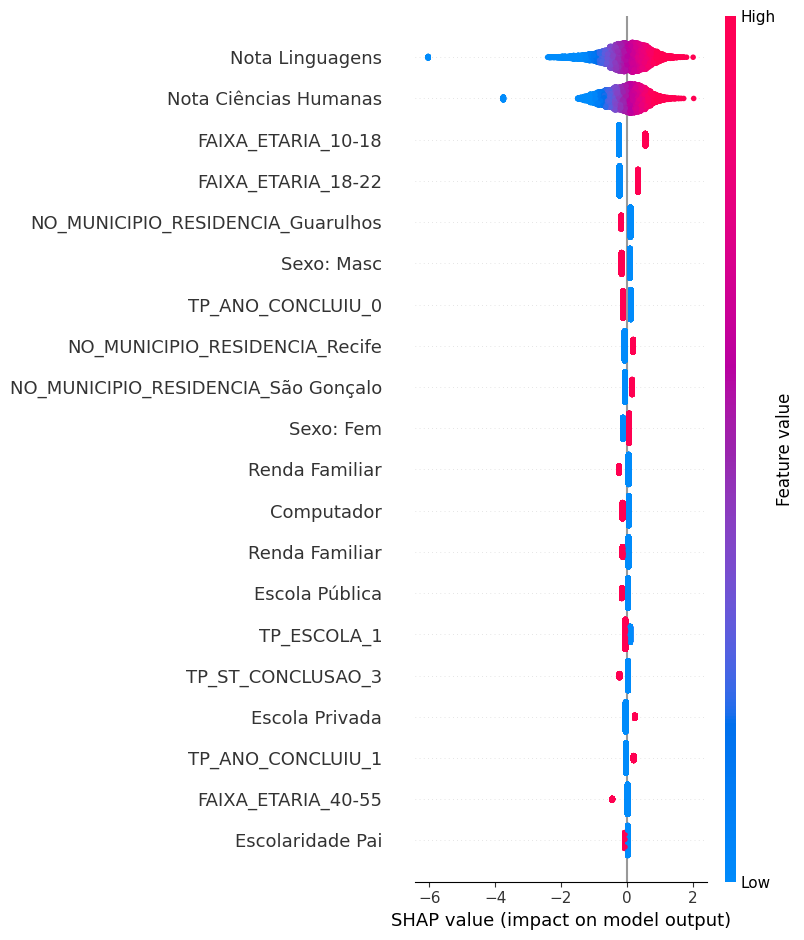


--- GRÁFICO 2: IMPORTÂNCIA GLOBAL ---


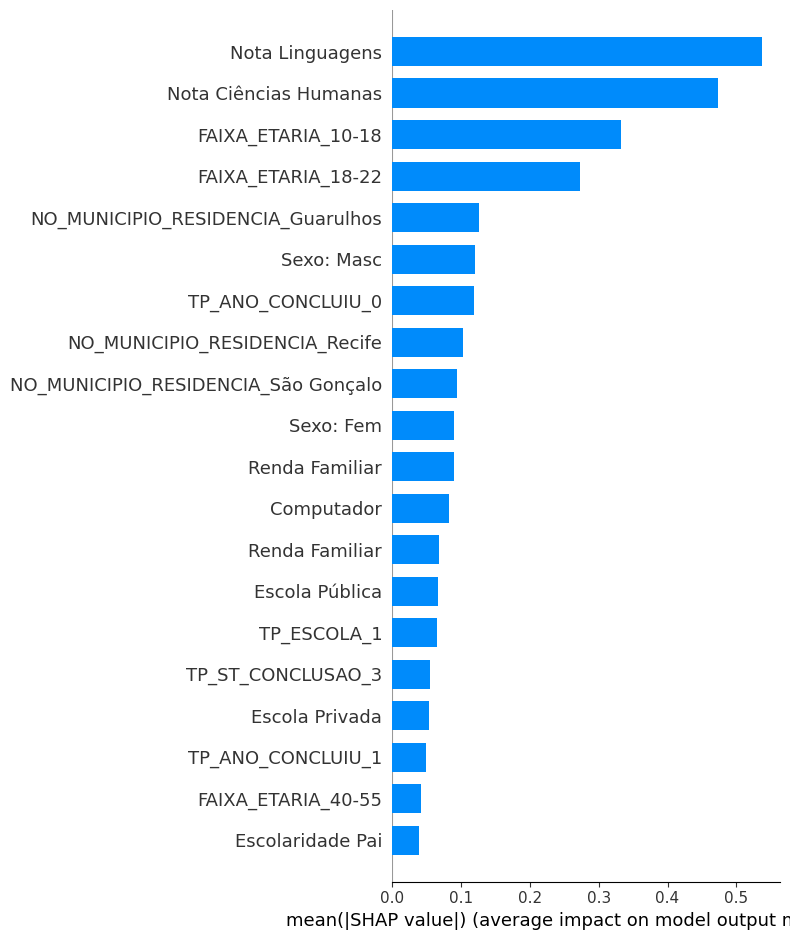

In [ ]:
try:
    import shap
except ImportError:
    print("Instalando biblioteca SHAP...")
    !pip install shap
    import shap

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

if not best_estimators:
    print("❌ ERRO: Sem modelos para explicar.")
else:
    # 1. Identificar o modelo vencedor
    best_model_name = df_metrics.iloc[0]['Método']
    best_model_pipeline = best_estimators[best_model_name]

    print(f"🏆 Gerando gráficos para: {best_model_name}")

    # 2. Transformar os dados
    preprocessor_step = best_model_pipeline.named_steps['preprocessor']
    model_step = best_model_pipeline.named_steps['model']

    X_transformed = preprocessor_step.transform(X)

    # 3. CONSTRUÇÃO MANUAL DOS NOMES (Para garantir que funcione)
    # Sabemos que as duas primeiras colunas SÃO AS NOTAS (definido no pipeline)
    feature_names = []

    # Adiciona as numéricas primeiro
    feature_names.append("Nota Ciências Humanas") # Feature 0
    feature_names.append("Nota Linguagens")       # Feature 1

    # Tenta pegar os nomes das outras (categóricas)
    try:
        raw_cat_names = preprocessor_step.named_transformers_['cat'].get_feature_names_out()
    except:
        raw_cat_names = [f"Var_Cat_{i}" for i in range(X_transformed.shape[1]-2)]

    # Dicionário de Tradução
    name_map = {
        'Q001': 'Escolaridade Pai', 'Q002': 'Escolaridade Mãe',
        'Q003': 'Profissão Pai',  'Q004': 'Profissão Mãe',
        'Q006': 'Renda Familiar', 'Q025': 'Acesso Internet',
        'Q024': 'Computador', 'TP_SEXO_M': 'Sexo: Masc', 'TP_SEXO_F': 'Sexo: Fem',
        'TP_ESCOLA_2': 'Escola Pública', 'TP_ESCOLA_3': 'Escola Privada'
    }

    # Limpa os nomes das categóricas
    for name in raw_cat_names:
        clean = name
        for key, val in name_map.items():
            if key in name:
                clean = val # Substitui pelo nome bonito
                break
        feature_names.append(clean)

    # Garante que a lista de nomes tenha o tamanho certo
    # Se sobrar ou faltar (pode acontecer no OneHot), preenchemos com genéricos
    if len(feature_names) < X_transformed.shape[1]:
        feature_names += [f"Extra_{i}" for i in range(X_transformed.shape[1] - len(feature_names))]
    elif len(feature_names) > X_transformed.shape[1]:
        feature_names = feature_names[:X_transformed.shape[1]]

    # 4. Criar DataFrame (O SHAP prefere DataFrame com nomes)
    if hasattr(X_transformed, "toarray"):
        X_transformed = X_transformed.toarray()

    X_df = pd.DataFrame(X_transformed, columns=feature_names)

    # 5. Calcular SHAP Values
    print("Calculando SHAP...")
    try:
        explainer = shap.Explainer(model_step, X_transformed)
        shap_values = explainer(X_transformed)
    except:
        # Fallback seguro
        X_sample = shap.utils.sample(X_transformed, 100)
        explainer = shap.KernelExplainer(model_step.predict, X_sample)
        shap_values = explainer.shap_values(X_transformed[:200])

    # 6. FORÇAR A TROCA DOS NOMES
    # Se shap_values for um objeto Explanation, forçamos os nomes nele
    if hasattr(shap_values, "feature_names"):
        shap_values.feature_names = feature_names

    # 7. PLOTAR
    print("\n--- GRÁFICO 1: IMPACTO DETALHADO ---")
    plt.figure(figsize=(12, 8))
    # Passamos X_df explicitamente para garantir
    shap.summary_plot(shap_values, X_df, show=True)

    print("\n--- GRÁFICO 2: IMPORTÂNCIA GLOBAL ---")
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values, X_df, plot_type="bar", show=True)